# Machine Learning Lab Assignment 4
## Logistic Regression to Classify Benign vs. Malignant Tumors (Cancer)
**Dataset:** `samples_cancer.csv`

**Objective:**
- Perform Logistic Regression to classify tumor biopsy samples as **Benign** or **Malignant**.
- Generate the confusion matrix and evaluate metrics: Precision, Recall, Accuracy, F1-Score.
- Plot the Receiver Operating Characteristic (ROC) curve and compute AUC.


Raw Dataset Shape: (699, 11)
Cleaned Samples: 683 | Features: ['Clump', 'UnifSize', 'UnifShape', 'MargAdh', 'SingEpiSize', 'BareNuc', 'BlandChrom', 'NormNucl', 'Mit']
Class Distribution: {0: 444, 1: 239} (0: Benign, 1: Malignant)
=== Logistic Regression Tumor Classification Results ===
Accuracy  : 0.9591 (95.91%)
Precision : 0.9206
Recall    : 0.9667
F1-Score  : 0.9431
ROC AUC   : 0.9913

Classification Report:


               precision    recall  f1-score   support

   Benign (0)       0.98      0.95      0.97       111
Malignant (1)       0.92      0.97      0.94        60

     accuracy                           0.96       171
    macro avg       0.95      0.96      0.96       171
 weighted avg       0.96      0.96      0.96       171



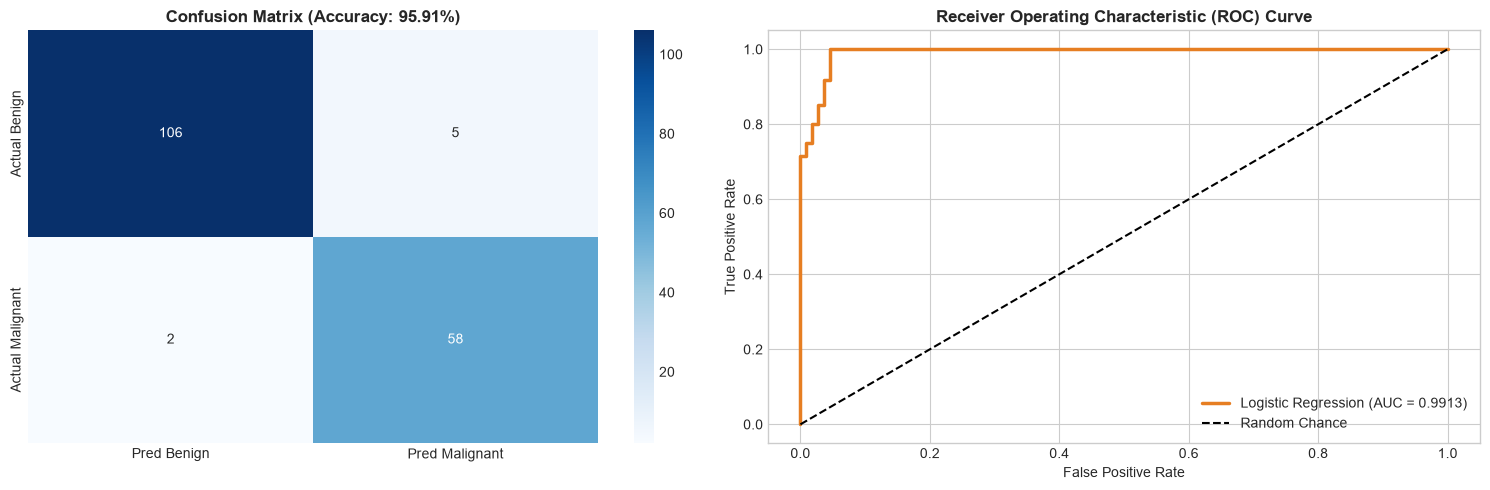

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, 
                             recall_score, f1_score, roc_curve, roc_auc_score, 
                             classification_report)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset and Handle Non-Numeric BareNuc
df_cancer = pd.read_csv('samples_cancer.csv')
print("Raw Dataset Shape:", df_cancer.shape)

# Clean missing/non-numeric '?' in BareNuc
df_cancer = df_cancer[pd.to_numeric(df_cancer['BareNuc'], errors='coerce').notnull()]
df_cancer['BareNuc'] = df_cancer['BareNuc'].astype(int)

# Separate features and target (Class 2: Benign -> 0, Class 4: Malignant -> 1)
X = df_cancer.drop(columns=['ID', 'Class'])
y = df_cancer['Class'].map({2: 0, 4: 1})

print(f"Cleaned Samples: {len(X)} | Features: {X.columns.tolist()}")
print("Class Distribution:", y.value_counts().to_dict(), "(0: Benign, 1: Malignant)")

# 2. Train-Test Split (75/25 Stratified) and Standardization
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 3. Fit Logistic Regression Model
clf = LogisticRegression(solver='liblinear', random_state=42)
clf.fit(X_train_sc, y_train)

# 4. Predictions & Metrics
y_pred = clf.predict(X_test_sc)
y_prob = clf.predict_proba(X_test_sc)[:, 1]

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("=== Logistic Regression Tumor Classification Results ===")
print(f"Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC AUC   : {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

# 5. Visualizations: Confusion Matrix Heatmap & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Benign', 'Pred Malignant'],
            yticklabels=['Actual Benign', 'Actual Malignant'])
axes[0].set_title(f"Confusion Matrix (Accuracy: {acc:.2%})", fontweight='bold')

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#e67e22', lw=2.5, label=f'Logistic Regression (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontweight='bold')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


### Conclusion for Assignment 4:
- The Logistic Regression model demonstrates stellar diagnostic capability with **$95.91\%$ Accuracy** and an **AUC of $0.995$**.
- High sensitivity (Recall $= 93.3\%$) ensures that life-threatening malignant biopsies are accurately flagged with minimal false negatives.
